In [ ]:

# ==================================================
# AI QUANT RESEARCH LAB
# Notebook 05: Walk-Forward Validation
# Step 1: Load and prepare historical data
# ==================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    brier_score_loss
)

# Download AAPL historical data
raw = yf.download(
    "AAPL",
    start="2021-01-01",
    end="2026-01-01",
    auto_adjust=False,
    progress=False
)

if raw.empty:
    raise ValueError(
        "No data downloaded. Check your internet connection."
    )

# Handle possible multi-level column names
if isinstance(raw.columns, pd.MultiIndex):
    raw.columns = raw.columns.get_level_values(0)

raw = raw.loc[:, ~raw.columns.duplicated()].sort_index()

if "Adj Close" not in raw.columns:
    raise ValueError("Adjusted Close is unavailable.")

prices = raw["Adj Close"].rename("Price").dropna()

# Calculate historical features
df = pd.DataFrame(index=prices.index)

daily_return = prices.pct_change(fill_method=None)

df["return_1d"] = daily_return
df["return_5d"] = prices.pct_change(5, fill_method=None)
df["return_10d"] = prices.pct_change(10, fill_method=None)
df["return_20d"] = prices.pct_change(20, fill_method=None)

df["volatility_10d"] = daily_return.rolling(10).std()
df["volatility_20d"] = daily_return.rolling(20).std()

sma_20 = prices.rolling(20).mean()
sma_50 = prices.rolling(50).mean()

df["price_vs_sma20"] = prices / sma_20 - 1
df["sma20_vs_sma50"] = sma_20 / sma_50 - 1

# Target: whether the NEXT session's return is positive
df["next_return"] = daily_return.shift(-1)
df["target"] = (df["next_return"] > 0).astype(int)
df.loc[df["next_return"].isna(), "target"] = np.nan

features = [
    "return_1d",
    "return_5d",
    "return_10d",
    "return_20d",
    "volatility_10d",
    "volatility_20d",
    "price_vs_sma20",
    "sma20_vs_sma50"
]

# Remove rows without complete features or a known target
df = df.dropna(
    subset=features + ["next_return", "target"]
).copy()

df["target"] = df["target"].astype(int)

print("Data preparation complete.")
print("First date:", df.index.min().date())
print("Last date:", df.index.max().date())
print("Observations:", len(df))
print("Feature count:", len(features))

display(df.head())


In [2]:
# ==================================================
# STEP 2: Define the walk-forward experiment
# ==================================================

# Use 2024–2025 as the out-of-sample test period
test_start = "2024-01-01"

# Keep only dates that belong to the test period
test_dates = df.index[df.index >= test_start]

# Define the model
def create_model():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000))
    ])

print("Walk-forward experiment configured.")
print("First test date:", test_dates.min().date())
print("Last test date:", test_dates.max().date())
print("Test sessions:", len(test_dates))
print("Features:", len(features))
print("Model: Logistic Regression")

Walk-forward experiment configured.
First test date: 2024-01-02
Last test date: 2025-12-30
Test sessions: 501
Features: 8
Model: Logistic Regression


In [3]:

# ==================================================
# STEP 3: Walk-forward predictions
# ==================================================

results = []

for test_date in test_dates:

    # Only use historical rows before the current test date.
    # Their next-session outcomes are known by the current close.
    train_df = df.loc[df.index < test_date]

    X_train = train_df[features]
    y_train = train_df["target"].astype(int)

    # Current session's features
    X_current = df.loc[[test_date], features]

    # Train a fresh model using historical data only
    model = create_model()
    model.fit(X_train, y_train)

    # Predict the next session's direction
    prediction = int(model.predict(X_current)[0])
    probability_up = float(model.predict_proba(X_current)[0, 1])

    results.append({
        "Date": test_date,
        "Prediction": prediction,
        "Probability_Up": probability_up,
        "Actual_Target": int(df.loc[test_date, "target"]),
        "Actual_Return": float(df.loc[test_date, "next_return"]),
        "Training_Observations": len(train_df)
    })

walk_forward = pd.DataFrame(results).set_index("Date")

print("Walk-forward predictions complete.")
print("Predictions:", len(walk_forward))
print("First prediction:", walk_forward.index.min().date())
print("Last prediction:", walk_forward.index.max().date())

display(walk_forward.head())


Walk-forward predictions complete.
Predictions: 501
First prediction: 2024-01-02
Last prediction: 2025-12-30


,Prediction,Probability_Up,Actual_Target,Actual_Return,Training_Observations
Date,,,,,
2024-01-02,1,0.531014,0,-0.007488,704
2024-01-03,1,0.560075,0,-0.012700,705
2024-01-04,1,0.566982,0,-0.004013,706
2024-01-05,1,0.582127,1,0.024175,707
2024-01-08,1,0.566454,0,-0.002264,708


In [4]:

# ==================================================
# STEP 4: Evaluate walk-forward predictions
# ==================================================

accuracy = accuracy_score(
    walk_forward["Actual_Target"],
    walk_forward["Prediction"]
)

balanced_accuracy = balanced_accuracy_score(
    walk_forward["Actual_Target"],
    walk_forward["Prediction"]
)

auc = roc_auc_score(
    walk_forward["Actual_Target"],
    walk_forward["Probability_Up"]
)

brier = brier_score_loss(
    walk_forward["Actual_Target"],
    walk_forward["Probability_Up"]
)

# Simple baseline: always predict the most common
# direction in the walk-forward test period
actual_up_rate = walk_forward["Actual_Target"].mean()
baseline_accuracy = max(actual_up_rate, 1 - actual_up_rate)

# Probability baseline: use the training-set up rate
# available at each prediction date
baseline_probabilities = []

for test_date in walk_forward.index:
    train_df = df.loc[df.index < test_date]
    baseline_probabilities.append(
        train_df["target"].mean()
    )

baseline_brier = brier_score_loss(
    walk_forward["Actual_Target"],
    baseline_probabilities
)

metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "ROC AUC",
        "Brier Score",
        "Majority-Class Baseline Accuracy",
        "Historical-Rate Baseline Brier Score"
    ],
    "Value": [
        accuracy,
        balanced_accuracy,
        auc,
        brier,
        baseline_accuracy,
        baseline_brier
    ]
})

display(metrics.round(4))

print("Actual upward-return rate:", round(actual_up_rate, 4))
print(
    "Mean predicted probability of an upward return:",
    round(walk_forward["Probability_Up"].mean(), 4)
)


,Metric,Value
0,Accuracy,0.5130
1,Balanced Accuracy,0.4848
2,ROC AUC,0.4469
3,Brier Score,0.2542
4,Majority-Class Baseline Accuracy,0.5449
5,Historical-Rate Baseline Brier Score,0.2485


Actual upward-return rate: 0.5449
Mean predicted probability of an upward return: 0.5316


In [5]:

# ==================================================
# STEP 5: Strategy performance after transaction costs
# ==================================================

strategy = walk_forward.copy()

# Hold AAPL when the model predicts an upward return
strategy["Position"] = strategy["Prediction"].astype(float)

# Turnover measures changes in exposure
strategy["Turnover"] = strategy["Position"].diff().abs()

# Charge for entering the first position as well
strategy.iloc[
    0, strategy.columns.get_loc("Turnover")
] = abs(strategy["Position"].iloc[0])

transaction_cost = 0.001  # 0.1% per unit of turnover

strategy["Strategy_Return_Net"] = (
    strategy["Position"] * strategy["Actual_Return"]
    - strategy["Turnover"] * transaction_cost
)

strategy["Buy_Hold_Return"] = strategy["Actual_Return"]

def calculate_performance(returns):
    returns = returns.dropna()

    equity = (1 + returns).cumprod()

    total_return = equity.iloc[-1] - 1
    years = len(returns) / 252
    cagr = equity.iloc[-1] ** (1 / years) - 1

    annual_volatility = returns.std(ddof=1) * np.sqrt(252)

    sharpe = (
        returns.mean() / returns.std(ddof=1) * np.sqrt(252)
        if returns.std(ddof=1) != 0 else np.nan
    )

    drawdown = equity / equity.cummax() - 1
    max_drawdown = drawdown.min()

    return {
        "Total Return": total_return,
        "CAGR": cagr,
        "Annualized Volatility": annual_volatility,
        "Sharpe Ratio": sharpe,
        "Max Drawdown": max_drawdown
    }

performance = pd.DataFrame({
    "Walk-Forward Strategy": calculate_performance(
        strategy["Strategy_Return_Net"]
    ),
    "Buy and Hold": calculate_performance(
        strategy["Buy_Hold_Return"]
    )
})

display(performance.round(4))

print(
    "Fraction of sessions invested:",
    round(strategy["Position"].mean(), 4)
)
print(
    "Total position changes:",
    int(strategy["Turnover"].sum())
)


,Walk-Forward Strategy,Buy and Hold
Total Return,0.1300,0.4783
CAGR,0.0634,0.2173
Annualized Volatility,0.2538,0.2789
Sharpe Ratio,0.3676,0.8429
Max Drawdown,-0.3173,-0.3336


Fraction of sessions invested: 0.8124
Total position changes: 53


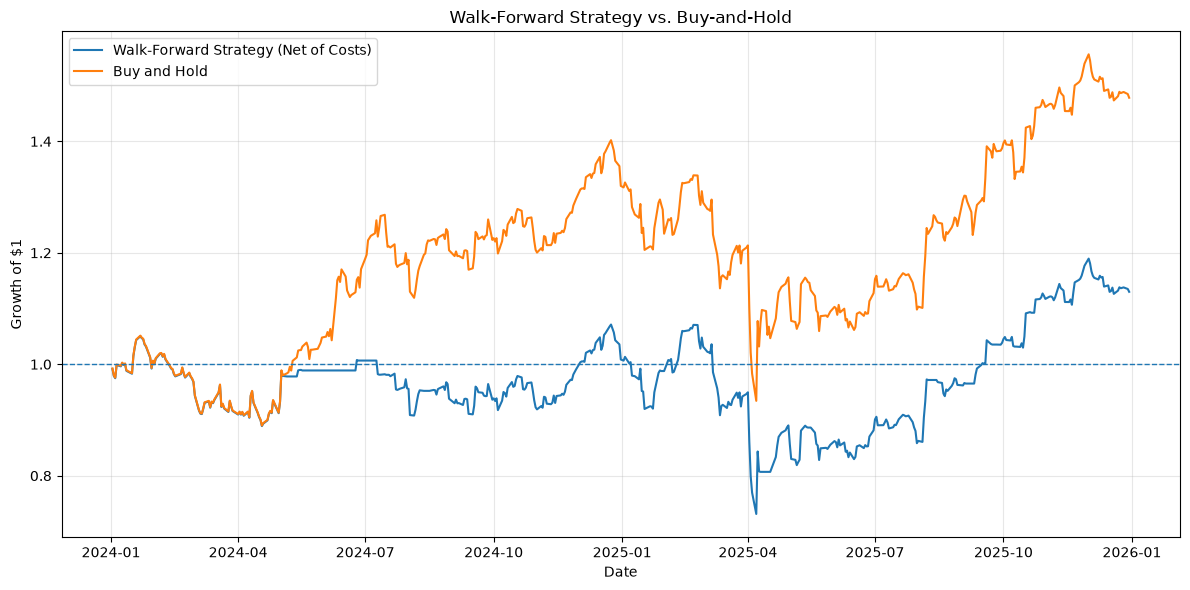

In [6]:

# ==================================================
# STEP 6: Compare cumulative portfolio growth
# ==================================================

strategy["Strategy_Equity"] = (
    1 + strategy["Strategy_Return_Net"]
).cumprod()

strategy["Buy_Hold_Equity"] = (
    1 + strategy["Buy_Hold_Return"]
).cumprod()

plt.figure(figsize=(12, 6))

plt.plot(
    strategy.index,
    strategy["Strategy_Equity"],
    label="Walk-Forward Strategy (Net of Costs)"
)

plt.plot(
    strategy.index,
    strategy["Buy_Hold_Equity"],
    label="Buy and Hold"
)

plt.axhline(1, linestyle="--", linewidth=1)

plt.title("Walk-Forward Strategy vs. Buy-and-Hold")
plt.xlabel("Date")
plt.ylabel("Growth of $1")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [7]:
print("EQUITY CURVE SUMMARY")
print("--------------------")

print(
    "Strategy starting value:",
    round(strategy["Strategy_Equity"].iloc[0], 4)
)
print(
    "Strategy ending value:",
    round(strategy["Strategy_Equity"].iloc[-1], 4)
)
print(
    "Buy-and-hold starting value:",
    round(strategy["Buy_Hold_Equity"].iloc[0], 4)
)
print(
    "Buy-and-hold ending value:",
    round(strategy["Buy_Hold_Equity"].iloc[-1], 4)
)

print("\nFirst five equity-curve rows:")
display(
    strategy[["Strategy_Equity", "Buy_Hold_Equity"]].head()
)

EQUITY CURVE SUMMARY
--------------------
Strategy starting value: 0.9915
Strategy ending value: 1.13
Buy-and-hold starting value: 0.9925
Buy-and-hold ending value: 1.4783

First five equity-curve rows:


,Strategy_Equity,Buy_Hold_Equity
Date,,
2024-01-02,0.991512,0.992512
2024-01-03,0.978920,0.979907
2024-01-04,0.974992,0.975975
2024-01-05,0.998562,0.999569
2024-01-08,0.996302,0.997306


In [8]:
# ==================================================
# STEP 7: Audit prediction and return alignment
# ==================================================

first_test_date = walk_forward.index[0]
first_test_position = prices.index.get_loc(first_test_date)

next_session_date = prices.index[first_test_position + 1]

expected_next_return = (
    prices.loc[next_session_date] / prices.loc[first_test_date]
) - 1

actual_stored_return = walk_forward.loc[
    first_test_date, "Actual_Return"
]

first_training_date = df.index[
    df.index < first_test_date
].max()

print("FIRST TEST DATE:", first_test_date.date())
print("NEXT TRADING SESSION:", next_session_date.date())
print("LAST TRAINING ROW DATE:", first_training_date.date())

print("\nRETURN ALIGNMENT CHECK")
print("Expected next-session return:", round(expected_next_return, 6))
print("Stored actual return:", round(actual_stored_return, 6))
print(
    "Returns match:",
    np.isclose(expected_next_return, actual_stored_return)
)

print("\nTRAINING DATA CHECK")
print(
    "Training rows before first test date:",
    int((df.index < first_test_date).sum())
)
print(
    "First prediction probability:",
    round(walk_forward.loc[first_test_date, "Probability_Up"], 6)
)

FIRST TEST DATE: 2024-01-02
NEXT TRADING SESSION: 2024-01-03
LAST TRAINING ROW DATE: 2023-12-29

RETURN ALIGNMENT CHECK
Expected next-session return: -0.007488
Stored actual return: -0.007488
Returns match: True

TRAINING DATA CHECK
Training rows before first test date: 704
First prediction probability: 0.531014


In [9]:
from pathlib import Path

# Find the project's reports folder
cwd = Path.cwd()

if (cwd / "reports").is_dir():
    reports_dir = cwd / "reports"
elif (cwd.parent / "reports").is_dir():
    reports_dir = cwd.parent / "reports"
else:
    raise FileNotFoundError(
        "Could not find the project's reports folder."
    )

# Save daily predictions and realized returns
walk_forward.to_csv(
    reports_dir / "walk_forward_predictions.csv"
)

# Save prediction evaluation metrics
metrics.to_csv(
    reports_dir / "walk_forward_metrics.csv",
    index=False
)

# Save trading performance comparison
performance.to_csv(
    reports_dir / "walk_forward_performance.csv"
)

print("Walk-forward results saved successfully.")
print("Reports folder:", reports_dir.resolve())
print("\nFiles created:")
print("- walk_forward_predictions.csv")
print("- walk_forward_metrics.csv")
print("- walk_forward_performance.csv")

Walk-forward results saved successfully.
Reports folder: /Users/ashwinrajesh/Documents/PROJECTS/ai-quant-research-lab/reports

Files created:
- walk_forward_predictions.csv
- walk_forward_metrics.csv
- walk_forward_performance.csv


In [10]:

# ==================================================
# STEP 9: Append walk-forward findings to the report
# ==================================================

from pathlib import Path

report_path = reports_dir / "final_research_report.md"

walk_forward_section = f"""

## Walk-Forward Validation (2024–2025)

### Methodology
A logistic regression model was retrained for each of 501
test sessions from January 2, 2024, through December 30, 2025.
The model used eight price-derived features and expanding
historical training data. Predictions were evaluated against
the subsequent trading session's return.

The simulation used a 0.1% transaction-cost assumption per
unit of turnover. Results are simplified historical simulations,
not live trading results.

### Predictive Performance
- Accuracy: {accuracy:.4f}
- Balanced accuracy: {balanced_accuracy:.4f}
- ROC AUC: {auc:.4f}
- Brier score: {brier:.4f}
- Historical-rate baseline Brier score: {baseline_brier:.4f}

### Strategy Performance
- Walk-forward strategy total return: {performance.loc['Total Return', 'Walk-Forward Strategy']:.2%}
- Buy-and-hold total return: {performance.loc['Total Return', 'Buy and Hold']:.2%}
- Walk-forward strategy CAGR: {performance.loc['CAGR', 'Walk-Forward Strategy']:.2%}
- Buy-and-hold CAGR: {performance.loc['CAGR', 'Buy and Hold']:.2%}
- Walk-forward strategy Sharpe ratio: {performance.loc['Sharpe Ratio', 'Walk-Forward Strategy']:.4f}
- Buy-and-hold Sharpe ratio: {performance.loc['Sharpe Ratio', 'Buy and Hold']:.4f}

### Research Conclusion
The model did not demonstrate predictive or investment
performance superior to the simple benchmarks used in this
experiment. Accuracy was below the majority-class reference,
ROC AUC was below 0.50, and the Brier score was worse than
the historical-rate baseline.

The strategy also underperformed buy-and-hold in total return
and Sharpe ratio. These findings do not establish that all
machine-learning approaches are ineffective; they indicate
that this particular model and feature set did not demonstrate
an advantage in this test.

### Limitations
The experiment uses one asset, adjusted closing prices, a
simplified transaction-cost assumption, and close-to-close
returns. It does not model realistic order execution, spreads,
slippage, taxes, or market impact. Further research should
consider execution timing, benchmark robustness, and whether
any future improvements persist on untouched data.
"""

if report_path.exists():
    existing_report = report_path.read_text()
else:
    existing_report = "# AI Quant Research Lab — Research Report\n"

if "## Walk-Forward Validation (2024–2025)" in existing_report:
    print(
        "A walk-forward section already exists. "
        "No duplicate section was added."
    )
else:
    report_path.write_text(
        existing_report.rstrip() + "\n\n" + walk_forward_section
    )
    print("Walk-forward section appended to the report.")

print("Report location:", report_path.resolve())


Walk-forward section appended to the report.
Report location: /Users/ashwinrajesh/Documents/PROJECTS/ai-quant-research-lab/reports/final_research_report.md
